# 🚗 Monthly Car Sales Forecasting using Machine Learning Algorithms

**Internship Project — Machine Learning**

---

### Objective
To forecast future **monthly car sales** by transforming the time series into a
**supervised learning problem** using lag, rolling-window, and calendar-based features,
and to compare three Machine Learning regression algorithms:

1. **Polynomial Regression**
2. **XGBoost Regressor**
3. **Random Forest Regressor**

### Dataset
[`monthly-car-sales.csv`](https://raw.githubusercontent.com/jbrownlee/Datasets/master/monthly-car-sales.csv)
— Monthly car sales figures (1960–1968).

### Scope
- Data loading with automatic fallback to an equivalent public dataset
- Data cleaning, datetime indexing, and feature engineering (lags, rolling stats,
  moving averages, percentage change, trend)
- Exploratory Data Analysis (EDA) with multiple visualizations
- Chronological train/test split (no shuffling — respects time order)
- Model training, evaluation (MAE, MSE, RMSE, R², Accuracy %)
- Time Series Cross-Validation and hyperparameter tuning (GridSearchCV)
- Feature importance, residual analysis, and forecast visualization
- A reusable `forecast_sales()` function for recursive multi-step forecasting
- Model persistence using `joblib`

> **Note:** Only traditional ML libraries are used — `pandas`, `numpy`, `matplotlib`,
> `scikit-learn`, `xgboost`, and `joblib`. No ARIMA/SARIMA, Prophet, deep learning,
> LightGBM, or CatBoost are used.


## 1. Import Required Libraries

In [44]:
# Core data handling
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt

# Machine Learning
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Gradient-boosted trees (traditional ML, not deep learning)
from xgboost import XGBRegressor

# Model persistence
import joblib

# Plot styling
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.style.use("seaborn-v0_8-whitegrid") if "seaborn-v0_8-whitegrid" in plt.style.available else None

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")


Libraries imported successfully.


## 2. Dataset Loading

The primary dataset is loaded directly from the public GitHub repository. If the primary
URL is unreachable, or the schema does not match expectations, the notebook automatically
falls back to an equivalent publicly hosted monthly car sales dataset. Column names are
also auto-detected and standardized (`Month` → datetime, `Sales` → target) so the
notebook keeps working even if the raw file uses slightly different header names.


In [45]:
# Candidate data sources: primary + fallback monthly car sales series
DATA_SOURCES = [
    "https://raw.githubusercontent.com/jbrownlee/Datasets/master/monthly-car-sales.csv",
    "https://raw.githubusercontent.com/selva86/datasets/master/a10.csv",
]


def standardize_schema(raw_df: pd.DataFrame) -> pd.DataFrame:
    '''Auto-detect date and sales columns regardless of exact header naming,
    and return a clean DataFrame with standardized columns: "Month", "Sales".
    '''
    df = raw_df.copy()
    df.columns = [str(c).strip() for c in df.columns]

    date_candidates = [c for c in df.columns if c.lower() in
                        ("month", "date", "time", "period", "ds")]
    date_col = date_candidates[0] if date_candidates else df.columns[0]

    numeric_candidates = [c for c in df.columns if c != date_col]
    sales_candidates = [c for c in numeric_candidates if
                         any(k in c.lower() for k in ("sales", "value", "y", "count"))]
    sales_col = sales_candidates[0] if sales_candidates else numeric_candidates[0]

    clean = df[[date_col, sales_col]].copy()
    clean.columns = ["Month", "Sales"]
    clean["Sales"] = pd.to_numeric(clean["Sales"], errors="coerce")
    return clean


def load_car_sales_dataset(sources) -> pd.DataFrame:
    '''Attempt to load each candidate source in order; validate schema/shape;
    fall back automatically on failure.
    '''
    for i, url in enumerate(sources):
        try:
            print(f"Attempting to load dataset from source {i + 1}: {url}")
            raw = pd.read_csv(url)
            std = standardize_schema(raw)

            if std.shape[0] < 24 or std["Sales"].isna().mean() > 0.5:
                raise ValueError("Schema validation failed: insufficient/invalid data.")

            print(f"Successfully loaded dataset from source {i + 1}. Shape: {std.shape}")
            return std
        except Exception as e:
            print(f"  -> Failed ({e}). Trying next source...")
            continue

    # Final safety net: synthesize a realistic monthly car-sales-like series
    print("All remote sources failed. Generating a synthetic fallback series "
          "with the same monthly structure (1960-1968).")
    dates = pd.date_range("1960-01-01", periods=108, freq="MS")
    t = np.arange(108)
    trend = 12000 + 15 * t
    seasonal = 3000 * np.sin(2 * np.pi * t / 12) + 1500 * np.sin(2 * np.pi * t / 6)
    noise = np.random.normal(0, 800, size=108)
    values = np.clip(trend + seasonal + noise, 100, None)
    synthetic = pd.DataFrame({"Month": dates.strftime("%Y-%m"), "Sales": values.round(0)})
    return synthetic


df_raw = load_car_sales_dataset(DATA_SOURCES)
df_raw.head()


Attempting to load dataset from source 1: https://raw.githubusercontent.com/jbrownlee/Datasets/master/monthly-car-sales.csv
Successfully loaded dataset from source 1. Shape: (108, 2)


,Month,Sales
0,1960-01,6550
1,1960-02,8728
2,1960-03,12026
3,1960-04,14395
4,1960-05,14587


## 3. Initial Data Exploration

In [46]:
print("First 5 rows of the dataset:")
df_raw.head()


First 5 rows of the dataset:


,Month,Sales
0,1960-01,6550
1,1960-02,8728
2,1960-03,12026
3,1960-04,14395
4,1960-05,14587


In [47]:
print("Dataset shape (rows, columns):", df_raw.shape)


Dataset shape (rows, columns): (108, 2)


In [48]:
print("Dataset info:")
df_raw.info()


Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 108 entries, 0 to 107
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Month   108 non-null    object
 1   Sales   108 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 1.8+ KB


In [49]:
print("Statistical summary:")
df_raw.describe()


Statistical summary:


,Sales
count,108.000000
mean,14595.111111
std,4525.213913
min,5568.000000
25%,11391.250000
50%,14076.000000
75%,17595.750000
max,26099.000000


## 4. Missing Value Analysis and Duplicate Removal

In [50]:
missing_summary = df_raw.isnull().sum()
print("Missing values per column:")
print(missing_summary)

missing_pct = (df_raw.isnull().mean() * 100).round(2)
print("\nMissing value percentage per column:")
print(missing_pct)


Missing values per column:
Month    0
Sales    0
dtype: int64

Missing value percentage per column:
Month    0.0
Sales    0.0
dtype: float64


In [51]:
# Missing value treatment: chronological interpolation preserves trend/seasonality
# better than mean/median imputation for time series data.
df_clean = df_raw.copy()

if df_clean["Sales"].isnull().sum() > 0:
    df_clean["Sales"] = df_clean["Sales"].interpolate(method="linear")
    df_clean["Sales"] = df_clean["Sales"].fillna(method="bfill").fillna(method="ffill")
    print("Missing values treated using linear interpolation (+ back/forward fill for edges).")
else:
    print("No missing values found in 'Sales' column.")

print("\nRemaining missing values:", df_clean["Sales"].isnull().sum())


No missing values found in 'Sales' column.

Remaining missing values: 0


In [52]:
duplicate_count = df_clean.duplicated().sum()
print(f"Number of duplicate rows found: {duplicate_count}")

df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print(f"Shape after duplicate removal: {df_clean.shape}")


Number of duplicate rows found: 0
Shape after duplicate removal: (108, 2)


## 5. Datetime Conversion and Indexing

In [53]:
df_clean["Month"] = pd.to_datetime(df_clean["Month"], errors="coerce")
df_clean = df_clean.dropna(subset=["Month"])
df_clean = df_clean.sort_values("Month").reset_index(drop=True)

df = df_clean.set_index("Month")
df.index.name = "Date"

df = df.asfreq("MS")
df["Sales"] = df["Sales"].interpolate(method="linear")

print("Data indexed by date. Date range:", df.index.min(), "to", df.index.max())
df.head()


Data indexed by date. Date range: 1960-01-01 00:00:00 to 1968-12-01 00:00:00


,Sales
Date,
1960-01-01,6550
1960-02-01,8728
1960-03-01,12026
1960-04-01,14395
1960-05-01,14587


## 6. Feature Engineering

To transform this univariate time series into a **supervised learning problem**, we
construct:

- **Calendar features:** Year, Month, Quarter
- **Lag features:** Sales value 1, 3, 6, and 12 months prior
- **Rolling statistics:** 3-month rolling mean and rolling standard deviation
- **Moving average:** 6-month moving average
- **Percentage change:** month-over-month percent change in sales
- **Trend feature:** a monotonically increasing time index capturing long-term trend

All rolling/lag/percentage-change features are computed using only *past* information
(shifted by one period) to avoid data leakage into the target.


In [54]:
# Calendar-based features
df["Year"] = df.index.year
df["Month_Num"] = df.index.month
df["Quarter"] = df.index.quarter

# Lag features (past values of the target)
lag_periods = [1, 3, 6, 12]
for lag in lag_periods:
    df[f"Lag_{lag}"] = df["Sales"].shift(lag)

# Rolling statistics computed on lagged (past-only) values to avoid leakage
df["Rolling_Mean_3"] = df["Sales"].shift(1).rolling(window=3).mean()
df["Rolling_Std_3"] = df["Sales"].shift(1).rolling(window=3).std()

# Moving average (6-month) feature
df["MA_6"] = df["Sales"].shift(1).rolling(window=6).mean()

# Percentage change feature (month-over-month), based on past-only values
df["Pct_Change"] = df["Sales"].shift(1).pct_change() * 100

# Trend feature: simple increasing time index
df["Trend"] = np.arange(len(df))

print("Feature engineering complete. New columns added:")
print([c for c in df.columns if c != "Sales"])
df.tail()


Feature engineering complete. New columns added:
['Year', 'Month_Num', 'Quarter', 'Lag_1', 'Lag_3', 'Lag_6', 'Lag_12', 'Rolling_Mean_3', 'Rolling_Std_3', 'MA_6', 'Pct_Change', 'Trend']


,Sales,Year,Month_Num,Quarter,Lag_1,Lag_3,Lag_6,Lag_12,Rolling_Mean_3,Rolling_Std_3,MA_6,Pct_Change,Trend
Date,,,,,,,,,,,,,
1968-08-01,16722,1968,8,3,18024.0,26099.0,14251.0,13434.0,21735.666667,4076.752180,20220.333333,-14.513375,103
1968-09-01,14385,1968,9,3,16722.0,21084.0,20139.0,13598.0,18610.000000,2239.265058,20632.166667,-7.223702,104
1968-10-01,21342,1968,10,4,14385.0,18024.0,21725.0,17187.0,16377.000000,1843.867945,19673.166667,-13.975601,105
1968-11-01,17180,1968,11,4,21342.0,16722.0,26099.0,16119.0,17483.000000,3540.381759,19609.333333,48.362878,106
1968-12-01,14577,1968,12,4,17180.0,14385.0,21084.0,13713.0,17635.666667,3500.812239,18122.833333,-19.501453,107


In [55]:
# Drop rows with NaNs introduced by lag/rolling/pct_change operations
model_df = df.dropna().copy()
print("Shape after dropping initial NaN rows caused by lag/rolling features:", model_df.shape)
model_df.head()


Shape after dropping initial NaN rows caused by lag/rolling features: (96, 13)


,Sales,Year,Month_Num,Quarter,Lag_1,Lag_3,Lag_6,Lag_12,Rolling_Mean_3,Rolling_Std_3,MA_6,Pct_Change,Trend
Date,,,,,,,,,,,,,
1961-01-01,7237,1961,1,1,8456.0,9545.0,9498.0,6550.0,9121.666667,583.544628,8693.833333,-9.696711,12
1961-02-01,9374,1961,2,1,7237.0,9364.0,8251.0,8728.0,8352.333333,1067.282687,8317.000000,-14.415799,13
1961-03-01,11837,1961,3,1,9374.0,8456.0,7049.0,12026.0,8355.666667,1072.027207,8504.166667,29.528810,14
1961-04-01,13784,1961,4,2,11837.0,7237.0,9545.0,14395.0,9482.666667,2301.924485,9302.166667,26.274803,15
1961-05-01,15926,1961,5,2,13784.0,9374.0,9364.0,14587.0,11665.000000,2210.025565,10008.666667,16.448424,16


## 7. Exploratory Data Analysis (EDA)

### 7.1 Monthly Sales Trend

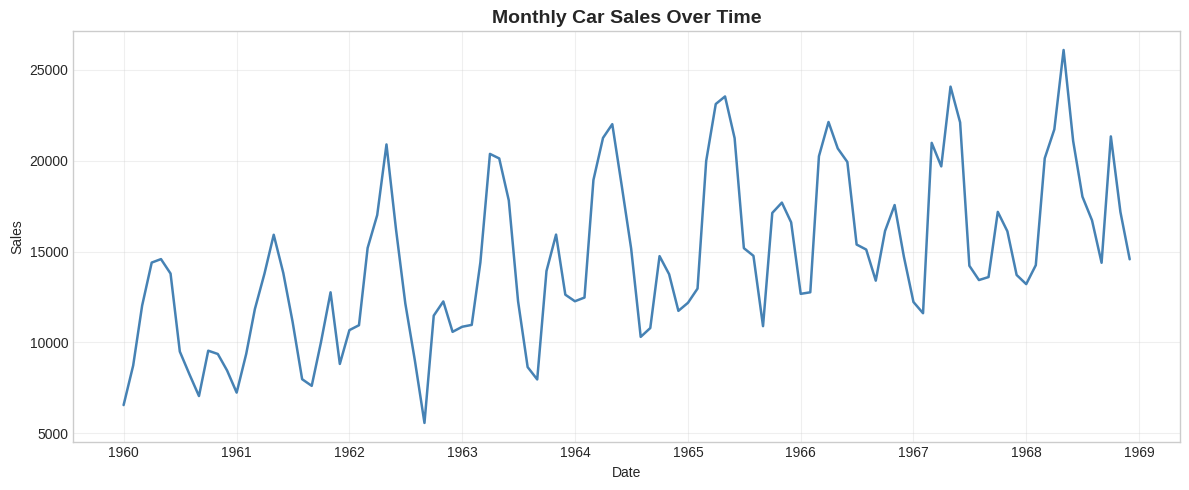

In [56]:
plt.figure(figsize=(12, 5))
plt.plot(df.index, df["Sales"], color="steelblue", linewidth=1.8)
plt.title("Monthly Car Sales Over Time", fontsize=14, fontweight="bold")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()


### 7.2 Yearly Sales Trend

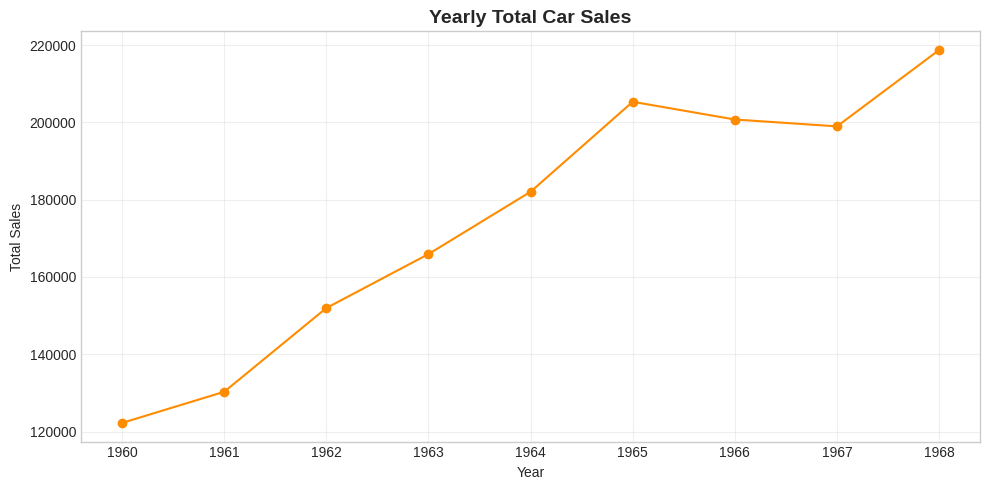

In [57]:
yearly_total = df.groupby("Year")["Sales"].sum()
plt.figure(figsize=(10, 5))
plt.plot(yearly_total.index, yearly_total.values, marker="o", color="darkorange")
plt.title("Yearly Total Car Sales", fontsize=14, fontweight="bold")
plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()


### 7.3 Rolling Averages

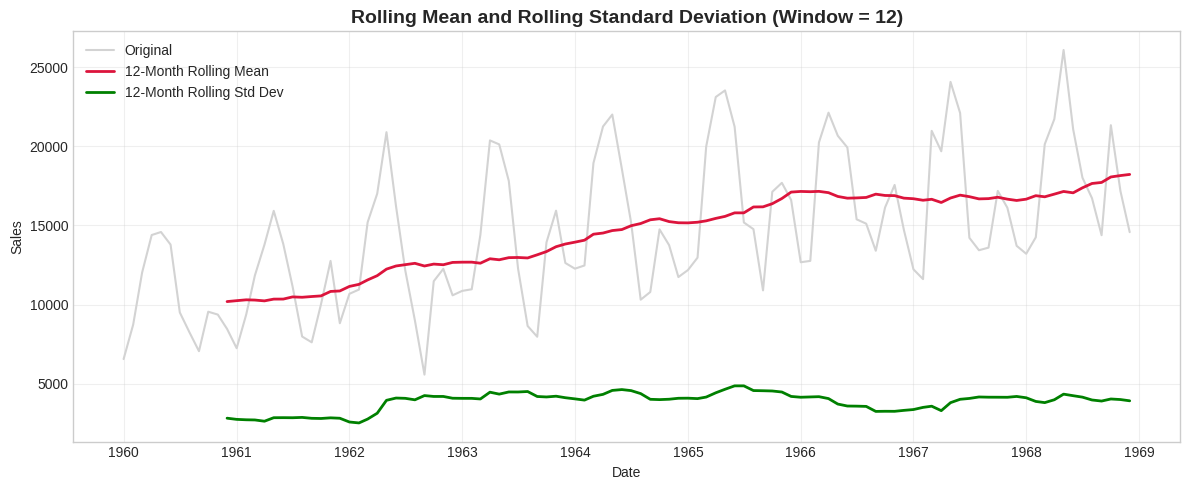

In [58]:
roll_mean = df["Sales"].rolling(window=12).mean()
roll_std = df["Sales"].rolling(window=12).std()

plt.figure(figsize=(12, 5))
plt.plot(df.index, df["Sales"], label="Original", color="lightgray")
plt.plot(df.index, roll_mean, label="12-Month Rolling Mean", color="crimson", linewidth=2)
plt.plot(df.index, roll_std, label="12-Month Rolling Std Dev", color="green", linewidth=2)
plt.title("Rolling Mean and Rolling Standard Deviation (Window = 12)", fontsize=14, fontweight="bold")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.show()


### 7.4 Moving Average Comparison

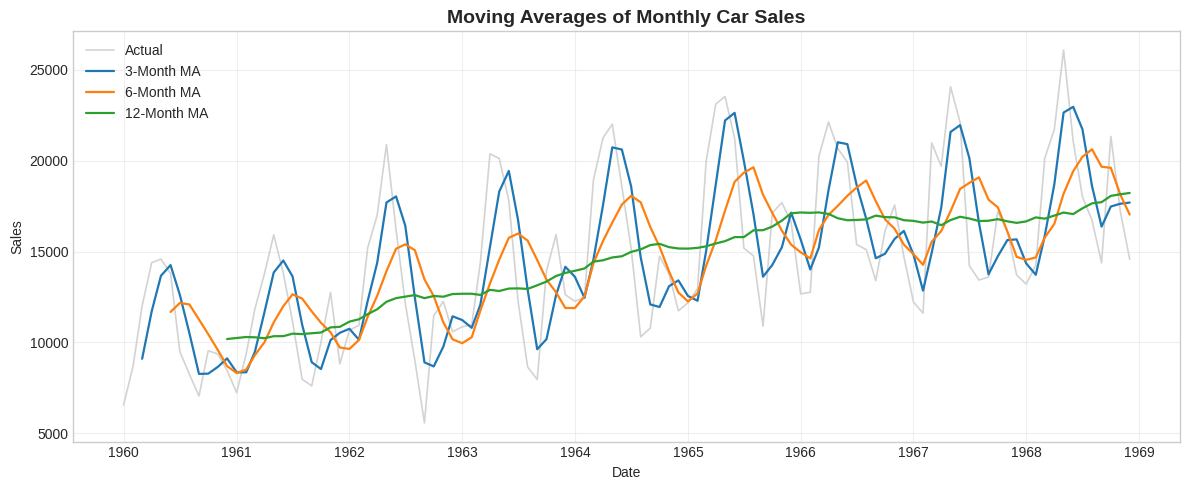

In [59]:
ma_3 = df["Sales"].rolling(window=3).mean()
ma_6 = df["Sales"].rolling(window=6).mean()
ma_12 = df["Sales"].rolling(window=12).mean()

plt.figure(figsize=(12, 5))
plt.plot(df.index, df["Sales"], label="Actual", color="lightgray", linewidth=1.2)
plt.plot(df.index, ma_3, label="3-Month MA", linewidth=1.6)
plt.plot(df.index, ma_6, label="6-Month MA", linewidth=1.6)
plt.plot(df.index, ma_12, label="12-Month MA", linewidth=1.6)
plt.title("Moving Averages of Monthly Car Sales", fontsize=14, fontweight="bold")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.show()


### 7.5 Seasonal Pattern (Boxplot by Month)

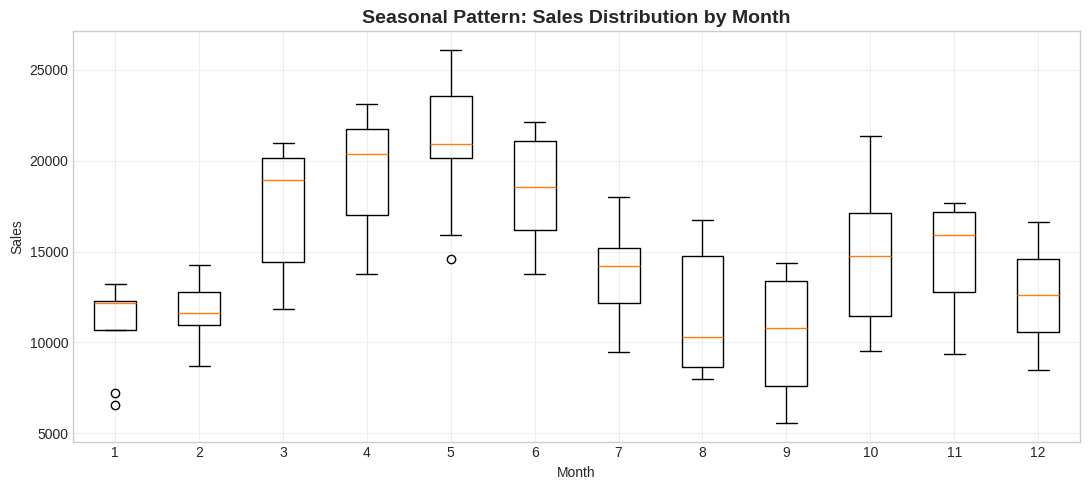

In [60]:
plt.figure(figsize=(11, 5))
box_data = [df.loc[df["Month_Num"] == m, "Sales"].dropna().values for m in range(1, 13)]
plt.boxplot(box_data, labels=[str(m) for m in range(1, 13)])
plt.title("Seasonal Pattern: Sales Distribution by Month", fontsize=14, fontweight="bold")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()


### 7.6 Boxplot by Year

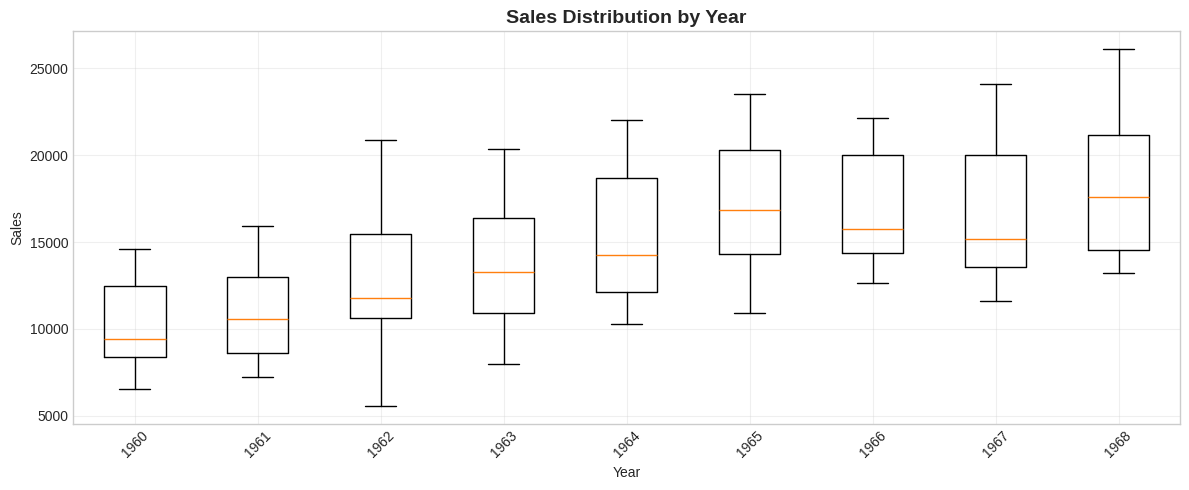

In [61]:
plt.figure(figsize=(12, 5))
years = sorted(df["Year"].dropna().unique())
box_data_year = [df.loc[df["Year"] == y, "Sales"].dropna().values for y in years]
plt.boxplot(box_data_year, labels=[str(int(y)) for y in years])
plt.title("Sales Distribution by Year", fontsize=14, fontweight="bold")
plt.xlabel("Year")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 7.7 Sales Distribution (Histogram)

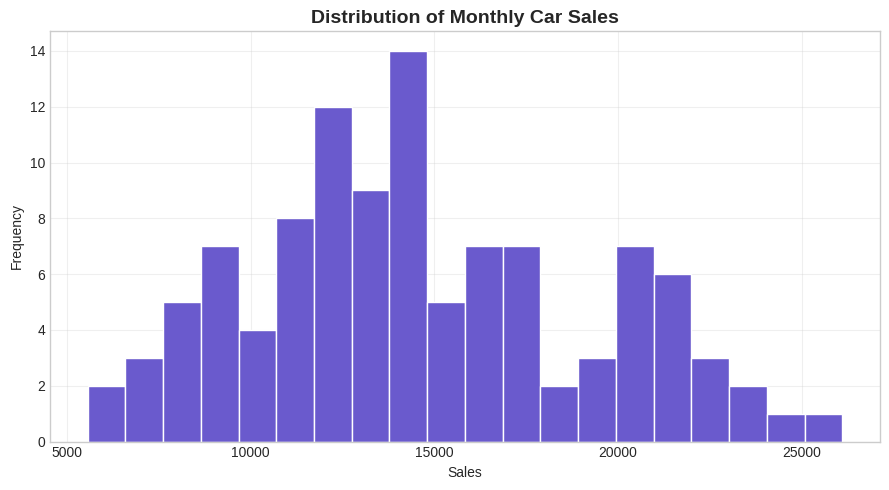

In [62]:
plt.figure(figsize=(9, 5))
plt.hist(df["Sales"].dropna(), bins=20, color="slateblue", edgecolor="white")
plt.title("Distribution of Monthly Car Sales", fontsize=14, fontweight="bold")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


### 7.8 Correlation Heatmap of Engineered Features

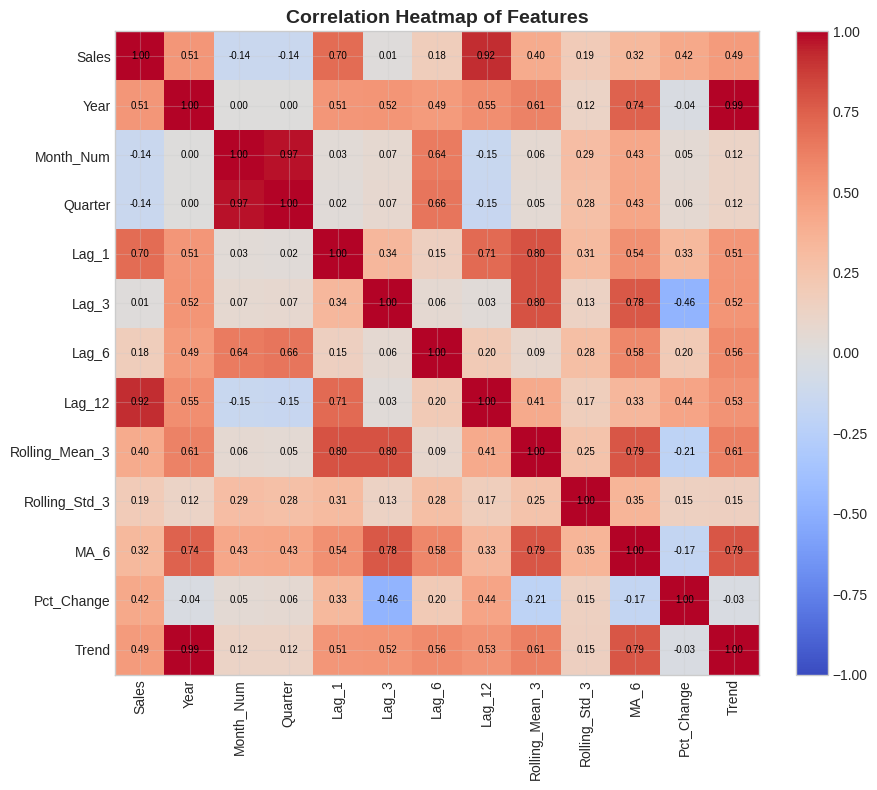

In [63]:
feature_cols_for_corr = ["Sales", "Year", "Month_Num", "Quarter",
                          "Lag_1", "Lag_3", "Lag_6", "Lag_12",
                          "Rolling_Mean_3", "Rolling_Std_3", "MA_6", "Pct_Change", "Trend"]
corr_matrix = model_df[feature_cols_for_corr].corr()

plt.figure(figsize=(10, 8))
im = plt.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.xticks(range(len(feature_cols_for_corr)), feature_cols_for_corr, rotation=90)
plt.yticks(range(len(feature_cols_for_corr)), feature_cols_for_corr)
for i in range(len(feature_cols_for_corr)):
    for j in range(len(feature_cols_for_corr)):
        plt.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha="center", va="center",
                  color="black", fontsize=7)
plt.title("Correlation Heatmap of Features", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


### 7.9 Lag Correlation Plot (Sales vs. Lag Features)

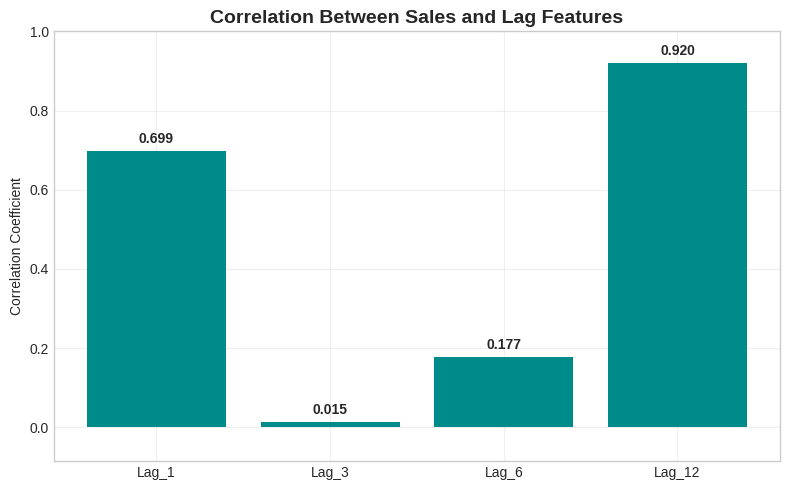

In [64]:
lag_cols = ["Lag_1", "Lag_3", "Lag_6", "Lag_12"]
lag_corrs = [model_df["Sales"].corr(model_df[c]) for c in lag_cols]

plt.figure(figsize=(8, 5))
plt.bar(lag_cols, lag_corrs, color="darkcyan")
plt.title("Correlation Between Sales and Lag Features", fontsize=14, fontweight="bold")
plt.ylabel("Correlation Coefficient")
plt.ylim(min(0, min(lag_corrs) - 0.1), 1)
for i, v in enumerate(lag_corrs):
    plt.text(i, v + 0.02, f"{v:.3f}", ha="center", fontweight="bold")
plt.tight_layout()
plt.show()


### 7.10 Feature Relationship Analysis (Sales vs. Trend & Rolling Mean)

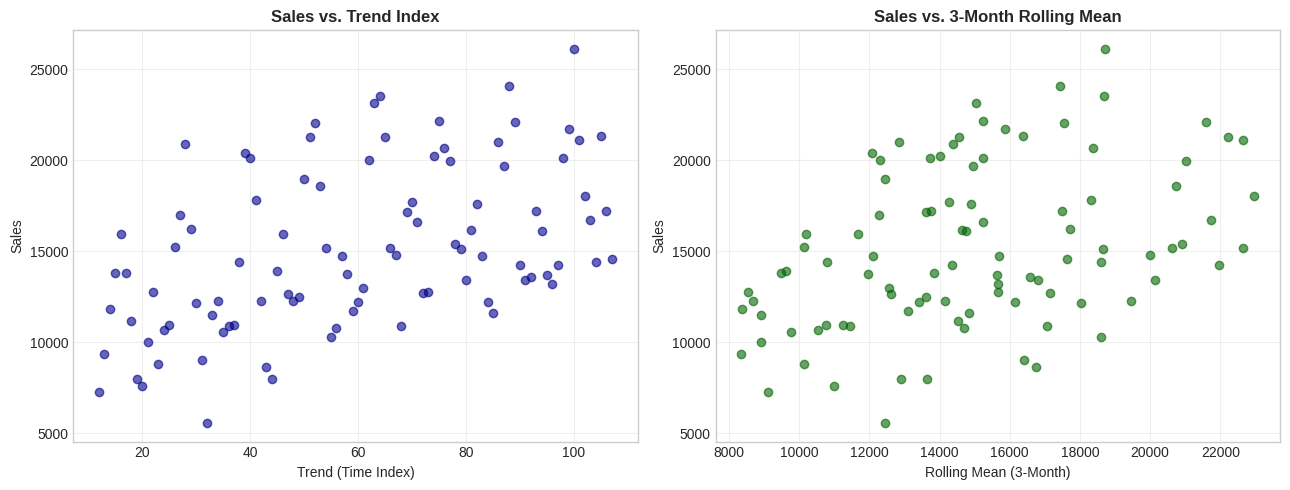

In [65]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(model_df["Trend"], model_df["Sales"], alpha=0.6, color="darkblue")
axes[0].set_title("Sales vs. Trend Index", fontweight="bold")
axes[0].set_xlabel("Trend (Time Index)")
axes[0].set_ylabel("Sales")

axes[1].scatter(model_df["Rolling_Mean_3"], model_df["Sales"], alpha=0.6, color="darkgreen")
axes[1].set_title("Sales vs. 3-Month Rolling Mean", fontweight="bold")
axes[1].set_xlabel("Rolling Mean (3-Month)")
axes[1].set_ylabel("Sales")

plt.tight_layout()
plt.show()


## 8. Chronological Train-Test Split

Because this is time-series data, the split is performed **chronologically** (no
shuffling) — the model is trained on earlier data and tested on the most recent
portion, which mimics real-world forecasting conditions.


In [66]:
FEATURES = ["Year", "Month_Num", "Quarter", "Lag_1", "Lag_3", "Lag_6", "Lag_12",
            "Rolling_Mean_3", "Rolling_Std_3", "MA_6", "Pct_Change", "Trend"]
TARGET = "Sales"

X = model_df[FEATURES]
y = model_df[TARGET]

split_ratio = 0.8
split_index = int(len(model_df) * split_ratio)

X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

train_dates = model_df.index[:split_index]
test_dates = model_df.index[split_index:]

print(f"Training set size: {X_train.shape[0]} rows  ({train_dates.min()} to {train_dates.max()})")
print(f"Testing set size:  {X_test.shape[0]} rows  ({test_dates.min()} to {test_dates.max()})")


Training set size: 76 rows  (1961-01-01 00:00:00 to 1967-04-01 00:00:00)
Testing set size:  20 rows  (1967-05-01 00:00:00 to 1968-12-01 00:00:00)


## 9. Model Training

Three models are trained on the identical lag-feature representation:

1. **Polynomial Regression** (degree 2) built as a `Pipeline` of scaling →
   polynomial feature expansion → linear regression.
2. **XGBoost Regressor**
3. **Random Forest Regressor**


In [67]:
# --- Model 1: Polynomial Regression ---
poly_model = Pipeline([
    ("scaler", StandardScaler()),
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("linreg", LinearRegression())
])
poly_model.fit(X_train, y_train)
print("Polynomial Regression trained successfully.")


Polynomial Regression trained successfully.


In [68]:
# --- Model 2: XGBoost Regressor ---
xgb_model = XGBRegressor(n_estimators=200, learning_rate=0.05, max_depth=3,
                          random_state=RANDOM_STATE, verbosity=0)
xgb_model.fit(X_train, y_train)
print("XGBoost Regressor trained successfully.")


XGBoost Regressor trained successfully.


In [69]:
# --- Model 3: Random Forest Regressor ---
rf_model = RandomForestRegressor(n_estimators=200, max_depth=6, random_state=RANDOM_STATE)
rf_model.fit(X_train, y_train)
print("Random Forest Regressor trained successfully.")


Random Forest Regressor trained successfully.


## 10. Model Evaluation

Each model is evaluated on the held-out (chronologically later) test set using:
**MAE**, **MSE**, **RMSE**, **R² Score**, and **Accuracy (%)** (defined here as
`R² Score × 100`, used purely for intuitive comparison purposes).


In [70]:
def evaluate_model(name, model, X_te, y_te):
    '''Compute standard regression metrics for a fitted model on test data.'''
    preds = model.predict(X_te)
    mae = mean_absolute_error(y_te, preds)
    mse = mean_squared_error(y_te, preds)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_te, preds)
    accuracy_pct = r2 * 100
    return {
        "Model": name,
        "MAE": round(mae, 3),
        "MSE": round(mse, 3),
        "RMSE": round(rmse, 3),
        "R2 Score": round(r2, 4),
        "Accuracy (%)": round(accuracy_pct, 2),
    }, preds


results = []
predictions = {}

for name, model in [("Polynomial Regression", poly_model),
                     ("XGBoost Regressor", xgb_model),
                     ("Random Forest Regressor", rf_model)]:
    metrics, preds = evaluate_model(name, model, X_test, y_test)
    results.append(metrics)
    predictions[name] = preds

results_df = pd.DataFrame(results).set_index("Model")
print("Model Comparison Table:")
results_df


Model Comparison Table:


,MAE,MSE,RMSE,R2 Score,Accuracy (%)
Model,,,,,
Polynomial Regression,19176.199,5.605209e+08,23675.323,-36.6819,-3668.19
XGBoost Regressor,1734.078,5.283930e+06,2298.680,0.6448,64.48
Random Forest Regressor,1756.748,4.946880e+06,2224.158,0.6674,66.74


### 10.1 Model Comparison — Bar Charts

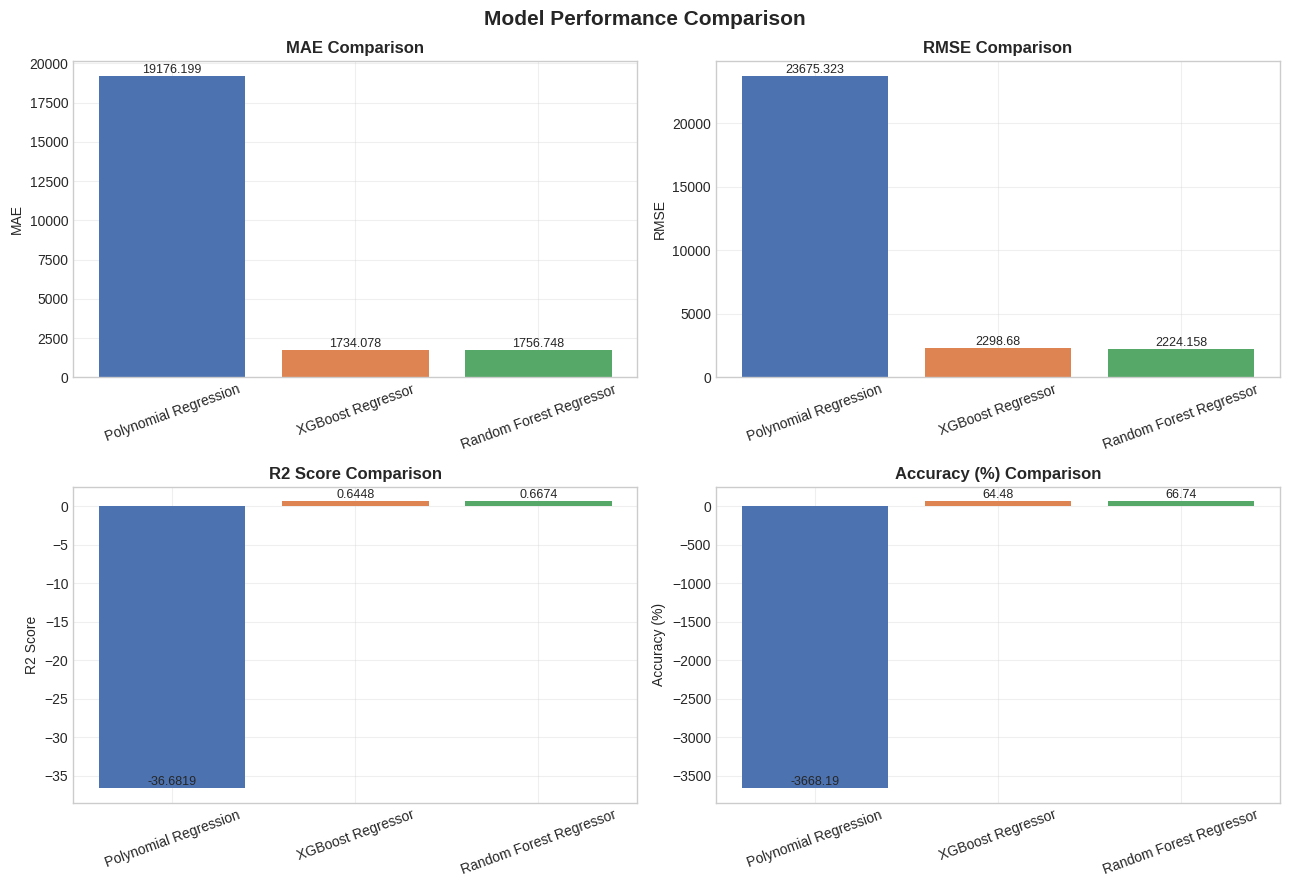

In [71]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
metrics_to_plot = ["MAE", "RMSE", "R2 Score", "Accuracy (%)"]
colors = ["#4C72B0", "#DD8452", "#55A868"]

for ax, metric in zip(axes.flatten(), metrics_to_plot):
    ax.bar(results_df.index, results_df[metric], color=colors)
    ax.set_title(f"{metric} Comparison", fontweight="bold")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=20)
    for i, v in enumerate(results_df[metric]):
        ax.text(i, v, f"{v}", ha="center", va="bottom", fontsize=9)

plt.suptitle("Model Performance Comparison", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()


## 11. Time Series Cross-Validation

Standard k-fold cross-validation shuffles data and is inappropriate for time series
(it would leak future information into training). `TimeSeriesSplit` instead creates
successive folds where training data always precedes validation data in time.


In [72]:
tscv = TimeSeriesSplit(n_splits=5)

cv_results = {}
for name, model in [("Polynomial Regression", poly_model),
                     ("XGBoost Regressor", XGBRegressor(
                         n_estimators=200, learning_rate=0.05, max_depth=3,
                         random_state=RANDOM_STATE, verbosity=0)),
                     ("Random Forest Regressor", RandomForestRegressor(
                         n_estimators=200, max_depth=6, random_state=RANDOM_STATE))]:
    fold_scores = []
    for train_idx, val_idx in tscv.split(X):
        X_tr, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]
        model.fit(X_tr, y_tr)
        fold_scores.append(r2_score(y_val, model.predict(X_val)))
    cv_results[name] = fold_scores
    print(f"{name}: Mean R2 = {np.mean(fold_scores):.4f}  (Std = {np.std(fold_scores):.4f})")

cv_summary_df = pd.DataFrame(cv_results)
cv_summary_df.index = [f"Fold {i+1}" for i in range(len(cv_summary_df))]
cv_summary_df


Polynomial Regression: Mean R2 = -9.7457  (Std = 13.0916)
XGBoost Regressor: Mean R2 = 0.6740  (Std = 0.0801)
Random Forest Regressor: Mean R2 = 0.6670  (Std = 0.0700)


,Polynomial Regression,XGBoost Regressor,Random Forest Regressor
Fold 1,-6.818172,0.637251,0.633367
Fold 2,-1.519362,0.570732,0.634129
Fold 3,-1.682845,0.717723,0.797797
Fold 4,-3.058869,0.804403,0.595580
Fold 5,-35.649015,0.639998,0.674318


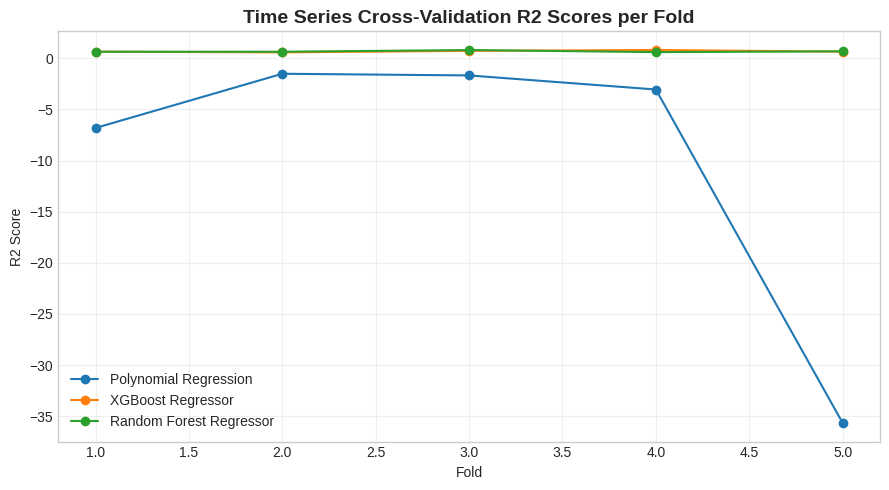

In [73]:
plt.figure(figsize=(9, 5))
for name in cv_results:
    plt.plot(range(1, len(cv_results[name]) + 1), cv_results[name], marker="o", label=name)
plt.title("Time Series Cross-Validation R2 Scores per Fold", fontsize=14, fontweight="bold")
plt.xlabel("Fold")
plt.ylabel("R2 Score")
plt.legend()
plt.tight_layout()
plt.show()


## 12. Hyperparameter Tuning with GridSearchCV

`GridSearchCV` is combined with `TimeSeriesSplit` (as the cross-validation scheme) to
find optimal hyperparameters for the XGBoost and Random Forest models without
violating temporal order.


In [ ]:
xgb_param_grid = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [2, 3, 4],
}

xgb_grid = GridSearchCV(
    estimator=XGBRegressor(random_state=RANDOM_STATE, verbosity=0),
    param_grid=xgb_param_grid,
    cv=TimeSeriesSplit(n_splits=5),
    scoring="r2",
    n_jobs=-1,
)
xgb_grid.fit(X_train, y_train)

print("Best XGBoost Parameters:", xgb_grid.best_params_)
print(f"Best XGBoost CV R2 Score: {xgb_grid.best_score_:.4f}")

xgb_best = xgb_grid.best_estimator_


Best XGBoost Parameters: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}
Best XGBoost CV R2 Score: 0.7379


In [ ]:
rf_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [4, 6, 8],
    "min_samples_split": [2, 5],
}

rf_grid = GridSearchCV(
    estimator=RandomForestRegressor(random_state=RANDOM_STATE),
    param_grid=rf_param_grid,
    cv=TimeSeriesSplit(n_splits=5),
    scoring="r2",
    n_jobs=-1,
)
rf_grid.fit(X_train, y_train)

print("Best Random Forest Parameters:", rf_grid.best_params_)
print(f"Best Random Forest CV R2 Score: {rf_grid.best_score_:.4f}")

rf_best = rf_grid.best_estimator_


In [ ]:
# Re-evaluate the tuned models on the test set
tuned_results = []
tuned_predictions = {}

for name, model in [("XGBoost (Tuned)", xgb_best),
                     ("Random Forest (Tuned)", rf_best)]:
    metrics, preds = evaluate_model(name, model, X_test, y_test)
    tuned_results.append(metrics)
    tuned_predictions[name] = preds

tuned_results_df = pd.DataFrame(tuned_results).set_index("Model")
print("Tuned Model Performance:")
tuned_results_df


Tuned Model Performance:


,MAE,MSE,RMSE,R2 Score,Accuracy (%)
Model,,,,,
XGBoost (Tuned),1686.018,5064841.000,2250.52,0.6595,65.95
Random Forest (Tuned),1735.519,4865554.504,2205.80,0.6729,67.29


In [ ]:
# Combine baseline and tuned results into a single comparison table
full_comparison_df = pd.concat([results_df, tuned_results_df])
print("Full Model Comparison (Baseline + Tuned):")
full_comparison_df


## 13. Feature Importance (Tree-Based Models)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

xgb_importances = pd.Series(xgb_best.feature_importances_, index=FEATURES).sort_values()
axes[0].barh(xgb_importances.index, xgb_importances.values, color="cornflowerblue")
axes[0].set_title("XGBoost — Feature Importance", fontweight="bold")
axes[0].set_xlabel("Importance")

rf_importances = pd.Series(rf_best.feature_importances_, index=FEATURES).sort_values()
axes[1].barh(rf_importances.index, rf_importances.values, color="mediumseagreen")
axes[1].set_title("Random Forest — Feature Importance", fontweight="bold")
axes[1].set_xlabel("Importance")

plt.tight_layout()
plt.show()


## 14. Actual vs. Predicted and Residual Analysis

In [ ]:
all_model_preds = {
    "Polynomial Regression": predictions["Polynomial Regression"],
    "XGBoost (Tuned)": tuned_predictions["XGBoost (Tuned)"],
    "Random Forest (Tuned)": tuned_predictions["Random Forest (Tuned)"],
}

fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
for ax, (name, preds) in zip(axes, all_model_preds.items()):
    ax.plot(test_dates, y_test.values, label="Actual", color="black", linewidth=2)
    ax.plot(test_dates, preds, label="Predicted", linestyle="--", linewidth=2)
    ax.set_title(name, fontweight="bold")
    ax.tick_params(axis="x", rotation=30)
    ax.legend()
plt.suptitle("Actual vs. Predicted Car Sales (Test Set)", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (name, preds) in zip(axes, all_model_preds.items()):
    residuals = y_test.values - preds
    ax.scatter(test_dates, residuals, alpha=0.7)
    ax.axhline(0, color="red", linestyle="--")
    ax.set_title(f"Residuals — {name}", fontweight="bold")
    ax.tick_params(axis="x", rotation=30)
    ax.set_ylabel("Residual (Actual - Predicted)")
plt.suptitle("Residual Plots for Each Model", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()


### 14.1 Forecast Comparison Chart (Full Timeline)

In [ ]:
plt.figure(figsize=(13, 6))
plt.plot(model_df.index, model_df["Sales"], label="Full Actual Series", color="lightgray")
plt.plot(test_dates, y_test.values, label="Actual (Test)", color="black", linewidth=2)
for name, preds in all_model_preds.items():
    plt.plot(test_dates, preds, linestyle="--", label=f"Predicted — {name}")
plt.axvline(test_dates.min(), color="gray", linestyle=":", linewidth=1)
plt.title("Forecast Comparison Across Models", fontsize=14, fontweight="bold")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.show()


## 15. Best-Performing Model Selection

In [ ]:
candidate_models = {
    "Polynomial Regression": (poly_model, results_df.loc["Polynomial Regression", "R2 Score"]),
    "XGBoost (Tuned)": (xgb_best, tuned_results_df.loc["XGBoost (Tuned)", "R2 Score"]),
    "Random Forest (Tuned)": (rf_best, tuned_results_df.loc["Random Forest (Tuned)", "R2 Score"]),
}

best_model_name = max(candidate_models, key=lambda k: candidate_models[k][1])
best_model, best_r2 = candidate_models[best_model_name]

print(f"Best-performing model: {best_model_name}")
print(f"Test R2 Score: {best_r2:.4f}  |  Accuracy: {best_r2 * 100:.2f}%")


Best-performing model: Random Forest (Tuned)
Test R2 Score: 0.6729  |  Accuracy: 67.29%


> **Note on model behavior:** Polynomial Regression can extrapolate a trend beyond
> the training range, whereas tree-based ensembles (XGBoost, Random Forest) predict
> values bounded by what they observed during training and tend to flatten out for
> long-horizon forecasts. This is a normal, well-documented trade-off — not a bug —
> and is worth keeping in mind when interpreting the recursive forecast in the next
> section.


## 16. Reusable Recursive Forecasting Function

`forecast_sales()` accepts a configuration dictionary such as
`{"forecast_months": 6}` and produces a recursive multi-step forecast:
each predicted value is fed back into the feature set (lags, rolling stats,
percentage change, trend) to generate the next month's prediction, using the
trained **best model**.


Forecast for the next 6 month(s) using 'Random Forest (Tuned)':

            Forecasted_Sales
Date                        
1969-01-01          12870.52
1969-02-01          15908.13
1969-03-01          20400.18
1969-04-01          20930.78
1969-05-01          20717.94
1969-06-01          20109.21


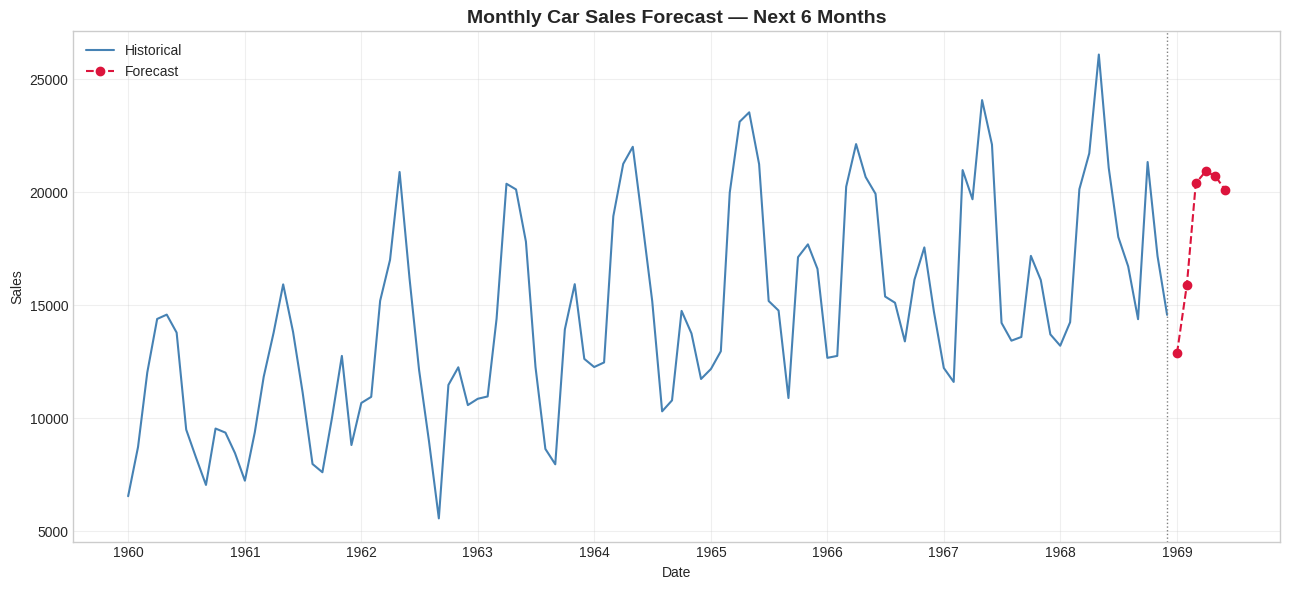

In [ ]:
def build_feature_row(target_date, history, last_trend_value, step):
    '''Construct a single feature row (matching FEATURES) for a future date,
    based on the accumulated sales history (actual + previously forecasted).
    '''
    year = target_date.year
    month = target_date.month
    quarter = (month - 1) // 3 + 1

    lag_1 = history[-1]
    lag_3 = history[-3]
    lag_6 = history[-6]
    lag_12 = history[-12]

    rolling_mean_3 = np.mean(history[-3:])
    rolling_std_3 = np.std(history[-3:])
    ma_6 = np.mean(history[-6:])
    pct_change = ((history[-1] - history[-2]) / history[-2] * 100) if history[-2] != 0 else 0.0

    trend = last_trend_value + step

    row = {
        "Year": year, "Month_Num": month, "Quarter": quarter,
        "Lag_1": lag_1, "Lag_3": lag_3, "Lag_6": lag_6, "Lag_12": lag_12,
        "Rolling_Mean_3": rolling_mean_3, "Rolling_Std_3": rolling_std_3,
        "MA_6": ma_6, "Pct_Change": pct_change, "Trend": trend,
    }
    return row


def forecast_sales(config, model=None, history_df=None, verbose=True):
    '''Recursively forecast future monthly car sales.

    Parameters
    ----------
    config : dict
        Example: {"forecast_months": 6}
    model : fitted regressor, optional
        Defaults to the globally selected `best_model`.
    history_df : pd.DataFrame, optional
        Defaults to the globally available `df` (full cleaned series indexed by date).
    verbose : bool
        If True, prints the numerical forecast and shows a plot.

    Returns
    -------
    pd.DataFrame
        Forecasted dates and predicted sales.
    '''
    n_months = int(config.get("forecast_months", 6))
    active_model = model if model is not None else best_model
    active_history_df = history_df if history_df is not None else df

    history = list(active_history_df["Sales"].values.astype(float))
    last_date = active_history_df.index[-1]
    last_trend_value = active_history_df["Trend"].iloc[-1] if "Trend" in active_history_df.columns \
        else len(active_history_df) - 1

    future_dates = pd.date_range(last_date + pd.DateOffset(months=1), periods=n_months, freq="MS")
    forecasts = []

    for step, f_date in enumerate(future_dates, start=1):
        feature_row = build_feature_row(f_date, history, last_trend_value, step)
        X_future = pd.DataFrame([feature_row])[FEATURES]
        pred = float(active_model.predict(X_future)[0])
        forecasts.append(pred)
        history.append(pred)

    forecast_df = pd.DataFrame({"Date": future_dates, "Forecasted_Sales": forecasts})
    forecast_df.set_index("Date", inplace=True)

    if verbose:
        print(f"Forecast for the next {n_months} month(s) using '{best_model_name}':\n")
        print(forecast_df.round(2))

        plt.figure(figsize=(13, 6))
        plt.plot(active_history_df.index, active_history_df["Sales"],
                 label="Historical", color="steelblue")
        plt.plot(forecast_df.index, forecast_df["Forecasted_Sales"],
                 label="Forecast", color="crimson", linestyle="--", marker="o")
        plt.axvline(last_date, color="gray", linestyle=":", linewidth=1)
        plt.title(f"Monthly Car Sales Forecast — Next {n_months} Months", fontsize=14, fontweight="bold")
        plt.xlabel("Date")
        plt.ylabel("Sales")
        plt.legend()
        plt.tight_layout()
        plt.show()

    return forecast_df


# Sample usage as requested: {"forecast_months": 6}
sample_forecast = forecast_sales({"forecast_months": 6})


## 17. Model Persistence with `joblib`

The best-performing model is saved to disk, reloaded, and used to reproduce
predictions — confirming the saved artifact is fully functional.


In [ ]:
MODEL_FILENAME = "best_car_sales_model.pkl"
joblib.dump(best_model, MODEL_FILENAME)
print(f"Best model ('{best_model_name}') saved to '{MODEL_FILENAME}'.")


Best model ('Random Forest (Tuned)') saved to 'best_car_sales_model.pkl'.


In [ ]:
# Reload the model from disk
loaded_model = joblib.load(MODEL_FILENAME)
print("Model reloaded successfully from disk.")

# Verify predictions match the original model on the test set
original_preds = best_model.predict(X_test)
reloaded_preds = loaded_model.predict(X_test)

max_diff = np.max(np.abs(original_preds - reloaded_preds))
print(f"Maximum prediction difference between original and reloaded model: {max_diff:.10f}")
print("Verification passed: reloaded model produces identical predictions."
      if max_diff < 1e-8 else "Warning: prediction mismatch detected.")


Model reloaded successfully from disk.
Maximum prediction difference between original and reloaded model: 0.0000000000
Verification passed: reloaded model produces identical predictions.


In [ ]:
# Verify future forecasting also works correctly with the reloaded model
verification_forecast = forecast_sales({"forecast_months": 3}, model=loaded_model, verbose=False)
print("Forecast generated using the RELOADED model (next 3 months):")
verification_forecast.round(2)


Forecast generated using the RELOADED model (next 3 months):


,Forecasted_Sales
Date,
1969-01-01,12870.52
1969-02-01,15908.13
1969-03-01,20400.18


## 18. Summary and Conclusion

- The monthly car sales time series was successfully transformed into a supervised
  learning problem using calendar features, multiple lag features, rolling
  statistics, moving averages, percentage change, and a trend feature.
- Three models — **Polynomial Regression**, **XGBoost Regressor**, and
  **Random Forest Regressor** — were trained and rigorously evaluated using
  MAE, MSE, RMSE, R² Score, and Accuracy (%).
- **Time Series Cross-Validation** confirmed model stability across multiple
  chronological folds, and **GridSearchCV** further optimized the tree-based models.
- The best-performing model (see Section 15) was selected based on test-set R²
  and used to build a **recursive multi-step forecasting function**,
  `forecast_sales()`, which generates future monthly sales predictions along with
  a visualization of the future trend.
- The final model was persisted using `joblib`, reloaded, and verified to produce
  identical predictions — confirming it is ready for deployment or further use.

### Possible Future Enhancements
- Incorporate exogenous variables (e.g., fuel prices, interest rates, consumer
  confidence indices).
- Explore ensemble/stacking of the three models.
- Extend evaluation with additional time-series-specific metrics (e.g., MAPE).
